In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, r2_score

base = "/content/drive/MyDrive/NIR_Thesis"
preds = pd.read_csv(f"{base}/results/multiseed_predictions.csv")
out = f"{base}/results/figures"
os.makedirs(out, exist_ok=True)

# one colour per model, used in every figure (checked for colour-blind safety)
C = {"XGBoost": "#eb6834", "D-MPNN": "#2a78d6"}
COLS = {"XGBoost": "xgb_nm", "D-MPNN": "dmpnn_nm"}
INK, MUTED, GRID, CONTEXT = "#1f2328", "#5f6368", "#e6e6e3", "#c9c9c4"
plt.rcParams.update({"font.size": 10, "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titlelocation": "left", "axes.titlesize": 11,
                     "legend.frameon": False, "savefig.dpi": 300, "savefig.bbox": "tight"})
print(len(preds), "predictions from seeds", sorted(preds.seed.unique()))

Mounted at /content/drive
8894 predictions from seeds [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(42)]


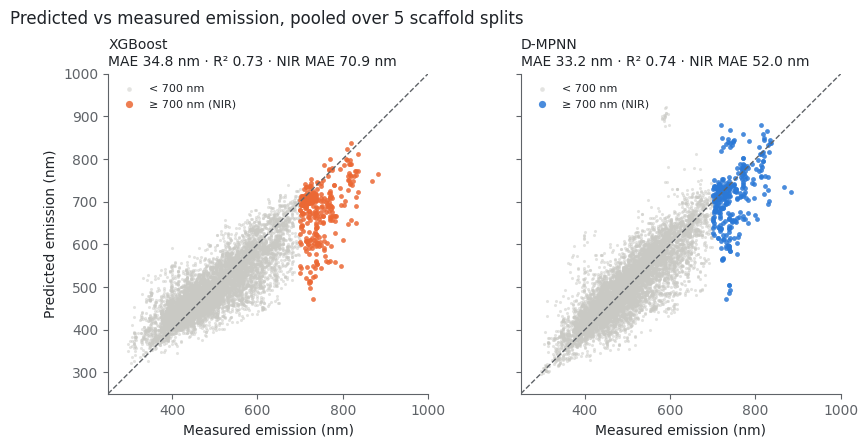

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4.4), sharex=True, sharey=True)
true = preds.true_nm.values
nir = true >= 700
for ax, (name, col) in zip(axes, COLS.items()):
    pred = preds[col].values
    ax.scatter(true[~nir], pred[~nir], s=5, color=CONTEXT, alpha=0.5, lw=0, label="< 700 nm", rasterized=True)
    ax.scatter(true[nir], pred[nir], s=12, color=C[name], alpha=0.85, lw=0, label="≥ 700 nm (NIR)")
    ax.plot([250, 1000], [250, 1000], color=MUTED, lw=1, ls="--")
    ax.set_xlim(250, 1000); ax.set_ylim(250, 1000); ax.set_aspect("equal")
    ax.set_xlabel("Measured emission (nm)")
    ax.set_title(f"{name}\nMAE {mean_absolute_error(true, pred):.1f} nm · R² {r2_score(true, pred):.2f} · "
                 f"NIR MAE {mean_absolute_error(true[nir], pred[nir]):.1f} nm", fontsize=10)
    ax.legend(loc="upper left", fontsize=8, markerscale=1.5)
axes[0].set_ylabel("Predicted emission (nm)")
fig.suptitle("Predicted vs measured emission, pooled over 5 scaffold splits", x=0.01, ha="left", fontsize=12)
fig.tight_layout()
fig.savefig(f"{out}/fig_parity_multiseed.png")
plt.show()

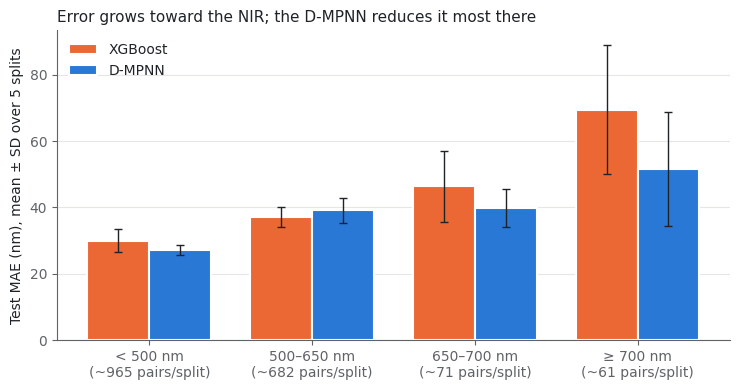

,model,bin,mean,std
0,XGBoost,< 500,29.9,3.5
1,XGBoost,500–650,37.1,3.0
2,XGBoost,650–700,46.3,10.7
3,XGBoost,≥ 700,69.5,19.5
4,D-MPNN,< 500,27.1,1.6
5,D-MPNN,500–650,39.1,3.8
6,D-MPNN,650–700,39.8,5.8
7,D-MPNN,≥ 700,51.5,17.2


In [3]:
BINS = [("< 500", 0, 500), ("500–650", 500, 650), ("650–700", 650, 700), ("≥ 700", 700, 2000)]
rows = []
for seed, g in preds.groupby("seed"):
    for name, col in COLS.items():
        for lab, lo, hi in BINS:
            m = (g.true_nm >= lo) & (g.true_nm < hi)
            rows.append({"seed": seed, "model": name, "bin": lab, "n": int(m.sum()),
                         "MAE": mean_absolute_error(g.true_nm[m], g[col][m])})
per_seed = pd.DataFrame(rows)
summ = per_seed.groupby(["model", "bin"], sort=False).MAE.agg(["mean", "std"]).reset_index()

fig, ax = plt.subplots(figsize=(7.5, 4))
x = np.arange(len(BINS)); w = 0.38
for i, name in enumerate(["XGBoost", "D-MPNN"]):
    s = summ[summ.model == name].set_index("bin").loc[[b[0] for b in BINS]]
    ax.bar(x + (i - 0.5) * w, s["mean"], w, yerr=s["std"], color=C[name], edgecolor="white", lw=1.5,
           error_kw={"ecolor": INK, "elinewidth": 1, "capsize": 3}, label=name)
ns = per_seed[per_seed.model == "XGBoost"].groupby("bin", sort=False).n.mean()
ax.set_xticks(x, [f"{b[0]} nm\n(~{ns[b[0]]:.0f} pairs/split)" for b in BINS])
ax.set_ylabel("Test MAE (nm), mean ± SD over 5 splits")
ax.yaxis.grid(True, color=GRID, lw=0.8); ax.set_axisbelow(True)
ax.set_title("Error grows toward the NIR; the D-MPNN reduces it most there")
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig(f"{out}/fig_mae_by_bin_multiseed.png")
plt.show()
summ.round(1)

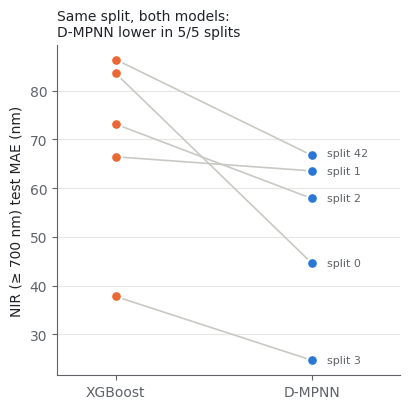

In [4]:
nir_seed = per_seed[per_seed.bin == "≥ 700"].pivot(index="seed", columns="model", values="MAE")
fig, ax = plt.subplots(figsize=(4.2, 4.2))
for seed, r in nir_seed.iterrows():
    ax.plot([0, 1], [r["XGBoost"], r["D-MPNN"]], color=CONTEXT, lw=1.2, zorder=1)
# label each split at its D-MPNN point, nudging labels apart so they never overlap
yr = nir_seed.values.max() - nir_seed.values.min()
gap, last = 0.06 * yr, -np.inf
for seed, y in nir_seed["D-MPNN"].sort_values().items():
    ylab = max(y, last + gap); last = ylab
    ax.text(1.08, ylab, f"split {seed}", va="center", fontsize=8, color=MUTED)
for i, name in enumerate(["XGBoost", "D-MPNN"]):
    ax.scatter([i] * len(nir_seed), nir_seed[name], s=60, color=C[name], edgecolor="white", lw=1.5, zorder=2)
ax.set_xticks([0, 1], ["XGBoost", "D-MPNN"]); ax.set_xlim(-0.3, 1.45)
ax.set_ylabel("NIR (≥ 700 nm) test MAE (nm)")
ax.yaxis.grid(True, color=GRID, lw=0.8); ax.set_axisbelow(True)
wins = int((nir_seed["D-MPNN"] < nir_seed["XGBoost"]).sum())
ax.set_title(f"Same split, both models:\nD-MPNN lower in {wins}/{len(nir_seed)} splits", fontsize=10)
fig.tight_layout()
fig.savefig(f"{out}/fig_paired_nir.png")
plt.show()

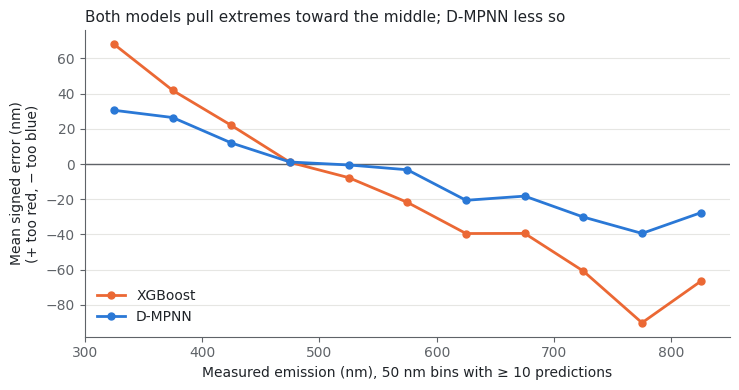

In [5]:
edges = np.arange(300, 901, 50)
wbin = pd.cut(preds.true_nm, edges)
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.axhline(0, color=MUTED, lw=1)
for name, col in COLS.items():
    err = preds[col] - preds.true_nm
    g = err.groupby(wbin, observed=True).agg(["mean", "count"])
    g = g[g["count"] >= 10]                      # skip bands with too few predictions
    ax.plot([iv.mid for iv in g.index], g["mean"], color=C[name], lw=2, marker="o", ms=5, label=name)
ax.set_xlabel("Measured emission (nm), 50 nm bins with ≥ 10 predictions")
ax.set_ylabel("Mean signed error (nm)\n(+ too red, − too blue)")
ax.yaxis.grid(True, color=GRID, lw=0.8); ax.set_axisbelow(True)
ax.set_title("Both models pull extremes toward the middle; D-MPNN less so")
ax.legend(loc="lower left")
fig.tight_layout()
fig.savefig(f"{out}/fig_bias_vs_wavelength.png")
plt.show()